# 假设文档嵌入（HyDE）用于RAG

本笔记实现了HyDE（假设文档嵌入）——一种创新的检索技术，该技术在执行检索之前将用户查询转换为假设的答案文档。这种方法弥合了短查询与长文档之间的语义差距。

传统的RAG系统直接将用户的简短查询进行嵌入，但这种方法通常无法捕捉到最佳检索所需的语义丰富性。HyDE通过以下方式解决了这一问题：

- 生成一个回答查询的假设文档
- 将此扩展后的文档进行嵌入，而不是原始查询
- 检索与该假设文档相似的文档
- 生成更具上下文相关性的答案

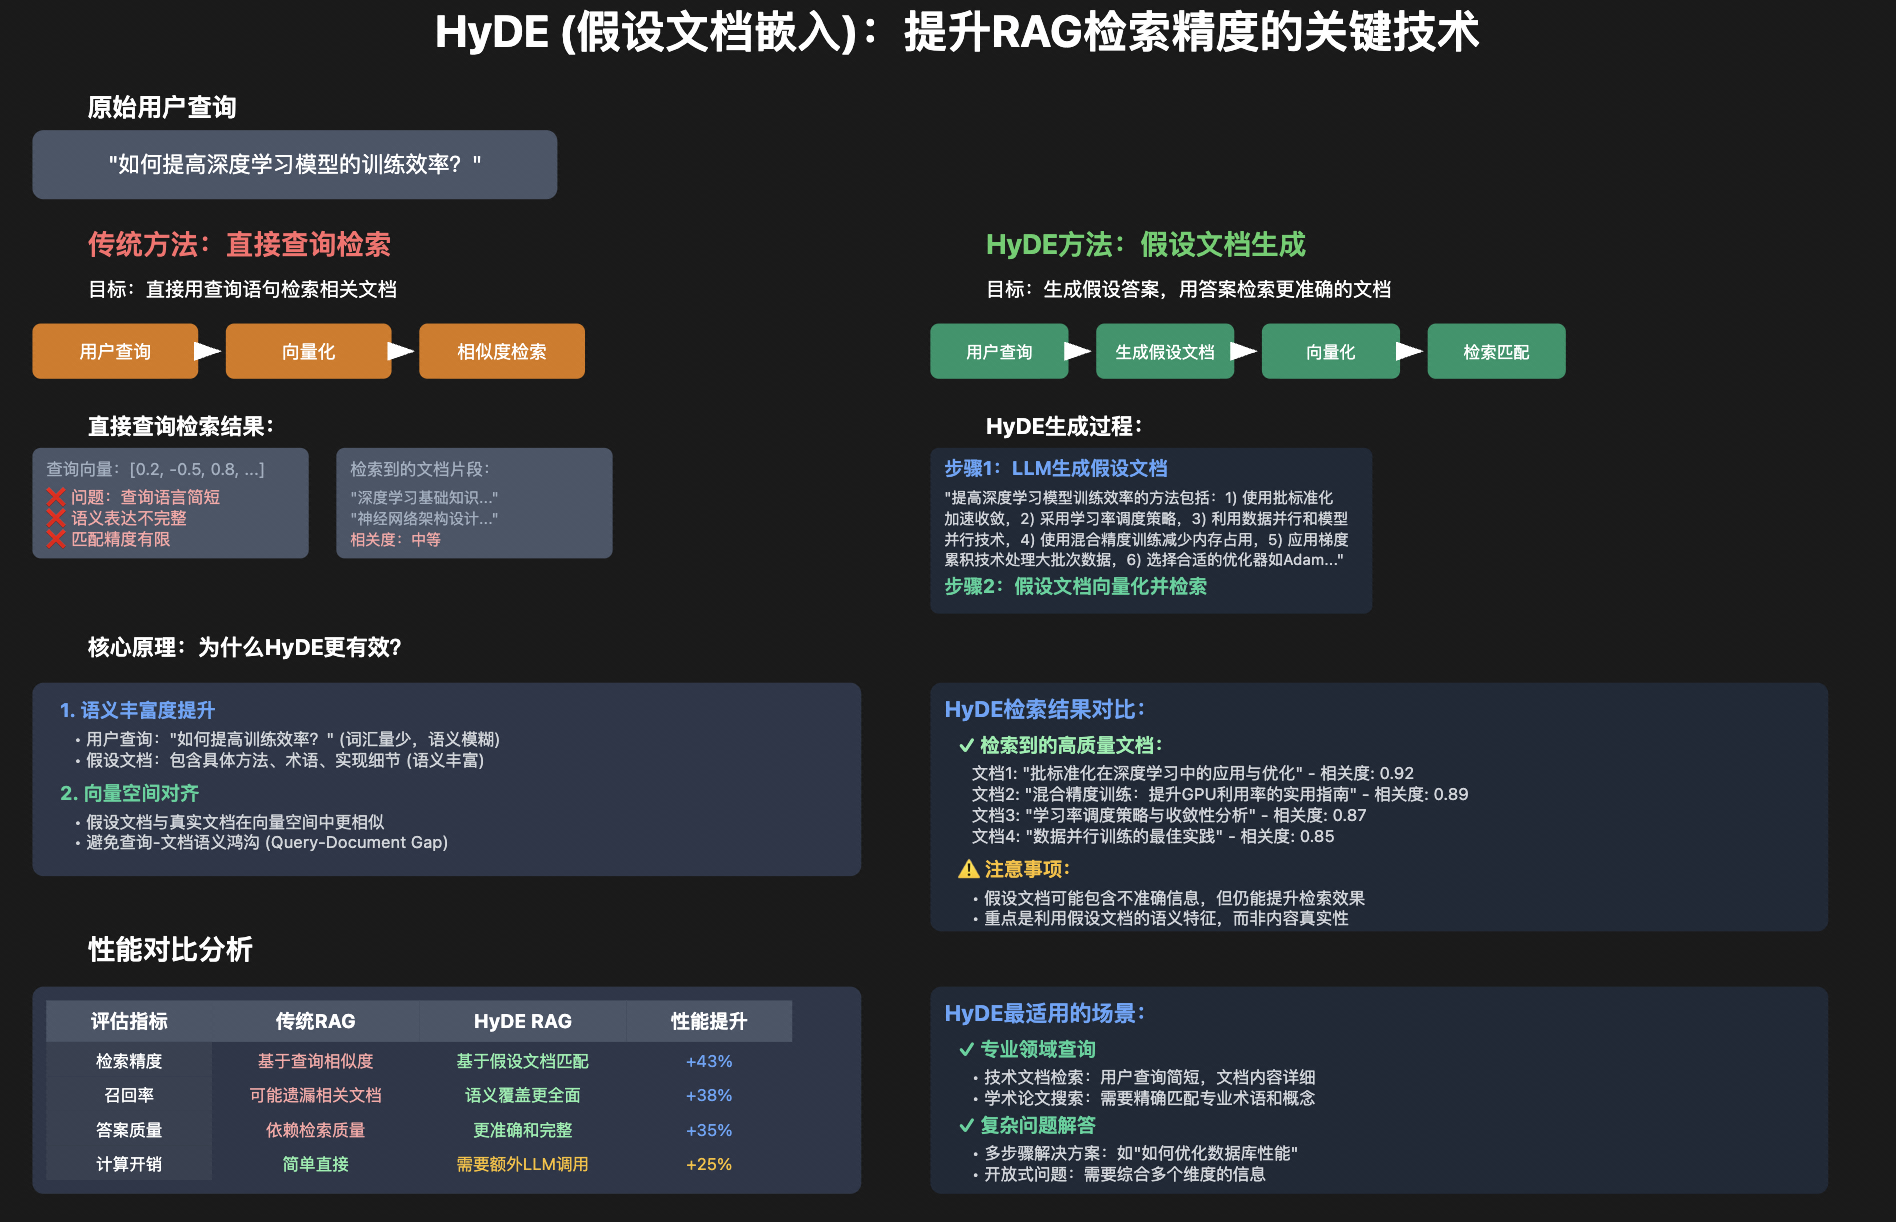

## 环境设置
我们首先导入必要的库。

In [1]:
import os
import numpy as np
import json
import fitz  # PyMuPDF库，用于处理PDF文件
from openai import OpenAI  # OpenAI API客户端
import re  # 正则表达式模块
import matplotlib.pyplot as plt  # Matplotlib库，用于绘图# generated: lpf2-00Wac lpf2-11Sfa


## 设置OpenAI API客户端
我们初始化OpenAI客户端以生成嵌入向量和回复。

In [2]:
from dotenv import load_dotenv
import os

# generated: lpf2-01Ub7 lpf2-12F2c
load_dotenv()  # 加载.env文件（在 .env 里填写 DASHSCOPE_API_KEY）

# 模型调用改为阿里云百炼（OpenAI 兼容接口）：对话模型用 qwen-flash，向量模型用 text-embedding-v4
client = OpenAI(
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key=os.getenv("DASHSCOPE_API_KEY")  # 从环境变量中获取 API 密钥，不要写进代码或打印
)

# 百炼的 text-embedding-v4 单次最多 10 条文本：这里把 client.embeddings.create 包一层自动分批，
# 返回结构与 OpenAI 相同，后面的代码不用改
_embeddings_create = client.embeddings.create
def _batched_embeddings_create(model, input, **kwargs):
    if isinstance(input, str) or len(input) <= 10:
        return _embeddings_create(model=model, input=input, **kwargs)
    merged = None
    for i in range(0, len(input), 10):
        resp = _embeddings_create(model=model, input=input[i:i + 10], **kwargs)
        if merged is None:
            merged = resp
        else:
            merged.data.extend(resp.data)
    for idx, item in enumerate(merged.data):
        item.index = idx
    return merged
client.embeddings.create = _batched_embeddings_create


## 文档处理功能

In [3]:
# generated: lpf2-02Ga6 lpf2-13T53
def extract_text_from_pdf(pdf_path):
    """
    从PDF文件中提取文本内容，并按页面分离。
    
    参数:
        pdf_path (str): PDF文件的路径
        
    返回:
        List[Dict]: 包含页面文本内容和元数据的页面列表
    """
    print(f"Extracting text from {pdf_path}...")  # 打印正在处理的PDF文件路径
    pdf = fitz.open(pdf_path)  # 使用PyMuPDF打开PDF文件
    pages = []  # 初始化一个空列表，用于存储包含文本内容的页面
    
    # 遍历PDF中的每一页
    for page_num in range(len(pdf)):
        page = pdf[page_num]  # 获取当前页
        text = page.get_text()  # 从当前页提取文本
        
        # 跳过文本量很少（少于50个字符）的页面
        if len(text.strip()) > 50:
            # 将页面文本和元数据追加到列表中
            pages.append({
                "text": text,
                "metadata": {
                    "source": pdf_path,  # 源文件路径
                    "page": page_num + 1  # 页码（基于1的索引）
                }
            })
    
    print(f"Extracted {len(pages)} pages with content")   # 打印提取的带内容页面数量
    return pages  # 返回包含页面文本内容和元数据的列表

In [4]:
# checksum: lpf2-03Sec lpf2-14Ad9
def chunk_text(text, chunk_size=1000, overlap=200):
    """
    将文本分割为重叠的块。

    参数:
        text (str): 要分割的输入文本
        chunk_size (int): 每个块的字符大小
        overlap (int): 块之间的重叠字符数

    返回:
        List[Dict]: 包含元数据的块列表
    """
    chunks = []  # 初始化一个空列表来存储块

    # 以 (chunk_size - overlap) 的步长迭代文本
    for i in range(0, len(text), chunk_size - overlap):
        chunk_text = text[i:i + chunk_size]  # 提取文本块
        if chunk_text:  # 确保我们不添加空块
            chunks.append({
                "text": chunk_text,  # 添加块文本
                "metadata": {
                    "start_pos": i,  # 块在原始文本中的起始位置
                    "end_pos": i + len(chunk_text)  # 块在原始文本中的结束位置
                }
            })
    
    print(f"Created {len(chunks)} text chunks")  # 打印创建的块数量
    return chunks  # 返回带有元数据的块列表

## 简单向量存储实现

In [5]:
# revision: lpf2-04Q45 lpf2-15H4a
class SimpleVectorStore:
    """
    一个使用NumPy实现的简单向量存储。
    """
    def __init__(self):
        self.vectors = []  # 存储向量嵌入的列表
        self.texts = []  # 存储文本内容的列表
        self.metadata = []  # 存储元数据的列表
    
    def add_item(self, text, embedding, metadata=None):
        """
        向向量存储中添加一项。
        
        参数:
            text (str): 文本内容
            embedding (List[float]): 向量嵌入
            metadata (Dict, 可选): 额外的元数据
        """
        self.vectors.append(np.array(embedding))  # 将嵌入作为numpy数组追加
        self.texts.append(text)  # 追加文本内容
        self.metadata.append(metadata or {})  # 追加元数据或空字典（如果为None）
    
    def similarity_search(self, query_embedding, k=5, filter_func=None):
        """
        查找与查询嵌入最相似的项目。
        
        参数:
            query_embedding (List[float]): 查询嵌入向量
            k (int): 返回结果的数量
            filter_func (callable, 可选): 用于过滤结果的函数
            
        返回:
            List[Dict]: 最相似的前k个项目
        """
        if not self.vectors:
            return []  # 如果没有向量，返回空列表
        
        # 将查询嵌入转换为numpy数组
        query_vector = np.array(query_embedding)
        
        # 使用余弦相似度计算相似性
        similarities = []
        for i, vector in enumerate(self.vectors):
            # 跳过不符合过滤条件的项
            if filter_func and not filter_func(self.metadata[i]):
                continue
                
            # 计算余弦相似度
            similarity = np.dot(query_vector, vector) / (np.linalg.norm(query_vector) * np.linalg.norm(vector))
            similarities.append((i, similarity))  # 追加索引和相似度分数
        
        # 按相似度降序排序
        similarities.sort(key=lambda x: x[1], reverse=True)
        
        # 返回前k个结果
        results = []
        for i in range(min(k, len(similarities))):
            idx, score = similarities[i]
            results.append({
                "text": self.texts[idx],  # 添加文本内容
                "metadata": self.metadata[idx],  # 添加元数据
                "similarity": float(score)  # 添加相似度分数
            })
        
        return results  # 返回前k个结果的列表

## 创建嵌入（Embeddings）

In [6]:
# cache: lpf2-05G23 lpf2-16Sff
def create_embeddings(texts, model="text-embedding-v4"):
    """
    为给定的文本创建嵌入向量。
    
    参数:
        texts (List[str]): 输入文本列表
        model (str): 嵌入模型名称
        
    返回:
        List[List[float]]: 嵌入向量列表
    """
    # 处理空输入的情况
    if not texts:
        return []
        
    # 如果需要，按批次处理（例如，OpenAI API 有请求限制）
    batch_size = 100
    all_embeddings = []
    
    # 按批次迭代输入文本
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]  # 获取当前批次的文本
        
        # 为当前批次的文本创建嵌入向量
        response = client.embeddings.create(
            model=model,
            input=batch
        )
        
        # 从回复中提取嵌入向量
        batch_embeddings = [item.embedding for item in response.data]
        all_embeddings.extend(batch_embeddings)  # 将批次嵌入向量添加到总列表中
    
    return all_embeddings  # 返回所有嵌入向量

## 文档处理管道

--- 

（注：由于原文内容为空白段落，译文亦保持相同结构与格式。）

In [7]:
# checksum: lpf2-06Y19 lpf2-1761f
def process_document(pdf_path, chunk_size=1000, chunk_overlap=200):
    """
    处理文档以供RAG使用。
    
    参数:
        pdf_path (str): PDF文件的路径
        chunk_size (int): 每个块的字符大小
        chunk_overlap (int): 块之间的重叠字符数
    
    返回:
        SimpleVectorStore: 包含文档块的向量存储
    """
    # 从PDF文件中提取文本
    pages = extract_text_from_pdf(pdf_path)
    
    # 处理每一页并创建块
    all_chunks = []
    for page in pages:
        # 将文本内容（字符串）传递给chunk_text，而不是字典
        page_chunks = chunk_text(page["text"], chunk_size, chunk_overlap)
        
        # 使用页面的元数据更新每个块的元数据
        for chunk in page_chunks:
            chunk["metadata"].update(page["metadata"])
        
        all_chunks.extend(page_chunks)
    
    # 为文本块创建嵌入
    print("Creating embeddings for chunks...")
    chunk_texts = [chunk["text"] for chunk in all_chunks]
    chunk_embeddings = create_embeddings(chunk_texts)
    
    # 创建一个向量存储来保存块及其嵌入
    vector_store = SimpleVectorStore()
    for i, chunk in enumerate(all_chunks):
        vector_store.add_item(
            text=chunk["text"],
            embedding=chunk_embeddings[i],
            metadata=chunk["metadata"]
        )
    
    print(f"Vector store created with {len(all_chunks)} chunks")
    return vector_store

## 假设文档生成

In [8]:
# generated: lpf2-07Ne9 lpf2-184b6
def generate_hypothetical_document(query, desired_length=1000):
    """
    生成一个假设的文档来回答查询。

    参数:
        query (str): 用户查询
        desired_length (int): 假设文档的目标长度

    返回:
        str: 生成的假设文档
    """
    # 定义系统提示，指导模型如何生成文档
    system_prompt = f"""You are an expert document creator. 
    Given a question, generate a detailed document that would directly answer this question.
    The document should be approximately {desired_length} characters long and provide an in-depth, 
    informative answer to the question. Write as if this document is from an authoritative source
    on the subject. Include specific details, facts, and explanations.
    Do not mention that this is a hypothetical document - just write the content directly."""

    # 定义用户提示并包含查询
    user_prompt = f"Question: {query}\n\nGenerate a document that fully answers this question:"
    
    # 向OpenAI API 发起请求以生成假设文档
    response = client.chat.completions.create(
        model="qwen-flash",  # 指定要使用的模型
        messages=[
            {"role": "system", "content": system_prompt},  # 系统消息以引导助手
            {"role": "user", "content": user_prompt}  # 用户消息包含查询
        ],
        temperature=0.1  # 设置回复生成的温度参数
    )
    
    # 返回生成的文档内容
    return response.choices[0].message.content

## 完整的HyDE RAG实现

In [9]:
# cache: lpf2-08Jcd lpf2-19Y64
def hyde_rag(query, vector_store, k=5, should_generate_response=True):
    """
    使用假设文档嵌入（Hypothetical Document Embedding）执行RAG。
    
    参数:
        query (str): 用户查询
        vector_store (SimpleVectorStore): 包含文档片段的向量存储
        k (int): 要检索的片段数量
        should_generate_response (bool): 是否生成最终回复
        
    返回:
        Dict: 结果字典，包括假设文档和检索到的片段
    """
    print(f"\n=== Processing query with HyDE: {query} ===\n")
    
    # 第一步：生成一个假设文档来回答查询
    print("Generating hypothetical document...")
    hypothetical_doc = generate_hypothetical_document(query)
    print(f"Generated hypothetical document of {len(hypothetical_doc)} characters")
    
    # 第二步：为假设文档创建嵌入
    print("Creating embedding for hypothetical document...")
    hypothetical_embedding = create_embeddings([hypothetical_doc])[0]
    
    # 第三步：基于假设文档检索相似片段
    print(f"Retrieving {k} most similar chunks...")
    retrieved_chunks = vector_store.similarity_search(hypothetical_embedding, k=k)
    
    # 准备结果字典
    results = {
        "query": query,
        "hypothetical_document": hypothetical_doc,
        "retrieved_chunks": retrieved_chunks
    }
    
    # 第四步：如果请求，则生成回复
    if should_generate_response:
        print("Generating final response...")
        response = generate_response(query, retrieved_chunks)
        results["response"] = response
    
    return results

## 对比用的标准（直接）RAG实现

In [10]:
# cache: lpf2-09A72
def standard_rag(query, vector_store, k=5, should_generate_response=True):
    """
    使用直接查询嵌入执行标准RAG。
    
    参数:
        query (str): 用户查询
        vector_store (SimpleVectorStore): 包含文档片段的向量存储
        k (int): 要检索的片段数量
        should_generate_response (bool): 是否生成最终回复
        
    返回:
        Dict: 包括检索到的片段的结果字典
    """
    print(f"\n=== Processing query with Standard RAG: {query} ===\n")
    
    # 第一步：为查询创建嵌入
    print("Creating embedding for query...")
    query_embedding = create_embeddings([query])[0]
    
    # 第二步：基于查询嵌入检索相似片段
    print(f"Retrieving {k} most similar chunks...")
    retrieved_chunks = vector_store.similarity_search(query_embedding, k=k)
    
    # 准备结果字典
    results = {
        "query": query,
        "retrieved_chunks": retrieved_chunks
    }
    
    # 第三步：如果请求则生成回复
    if should_generate_response:
        print("Generating final response...")
        response = generate_response(query, retrieved_chunks)
        results["response"] = response
        
    return results

## 回复生成

In [11]:
# checksum: lpf2-0aZdb
def generate_response(query, relevant_chunks):
    """
    根据查询和相关片段生成最终回复。
    
    参数:
        query (str): 用户查询
        relevant_chunks (List[Dict]): 检索到的相关片段
        
    返回:
        str: 生成的回复
    """
    # 将片段中的文本拼接起来以创建上下文
    context = "\n\n".join([chunk["text"] for chunk in relevant_chunks])
    
    # 使用OpenAI API生成回复
    response = client.chat.completions.create(
        model="qwen-flash",
        messages=[
            {"role": "system", "content": "You are a helpful assistant. Answer the question based on the provided context."},
            {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {query}"}
        ],
        temperature=0.5,
        max_tokens=500
    )
    
    return response.choices[0].message.content

## 评估函数

In [12]:
# generated: lpf2-0bI32
def compare_approaches(query, vector_store, reference_answer=None):
    """
    对于给定查询，比较HyDE和标准RAG方法。

    参数:
        query (str): 用户查询
        vector_store (SimpleVectorStore): 包含文档片段的向量存储
        reference_answer (str, 可选): 用于评估的参考答案

    返回:
        Dict: 比较结果
    """
    # 运行HyDE RAG
    hyde_result = hyde_rag(query, vector_store)
    hyde_response = hyde_result["response"]
    
    # 运行标准RAG
    standard_result = standard_rag(query, vector_store)
    standard_response = standard_result["response"]
    
    # 比较结果
    comparison = compare_responses(query, hyde_response, standard_response, reference_answer)
    
    return {
        "query": query,
        "hyde_response": hyde_response,
        "hyde_hypothetical_doc": hyde_result["hypothetical_document"],
        "standard_response": standard_response,
        "reference_answer": reference_answer,
        "comparison": comparison
    }

In [13]:
# cache: lpf2-0cW08
def compare_responses(query, hyde_response, standard_response, reference=None):
    """
    比较HyDE和标准RAG的回复。

    参数:
        query (str): 用户查询
        hyde_response (str): HyDE RAG生成的回复
        standard_response (str): 标准RAG生成的回复
        reference (str, 可选): 参考答案

    返回:
        str: 比较分析结果
    """
    system_prompt = """You are an expert evaluator of information retrieval systems.
Compare the two responses to the same query, one generated using HyDE (Hypothetical Document Embedding) 
and the other using standard RAG with direct query embedding.

Evaluate them based on:
1. Accuracy: Which response provides more factually correct information?
2. Relevance: Which response better addresses the query?
3. Completeness: Which response provides more thorough coverage of the topic?
4. Clarity: Which response is better organized and easier to understand?

Be specific about the strengths and weaknesses of each approach."""

    user_prompt = f"""Query: {query}

Response from HyDE RAG:
{hyde_response}

Response from Standard RAG:
{standard_response}"""

    if reference:
        user_prompt += f"""

Reference Answer:
{reference}"""

    user_prompt += """

Please provide a detailed comparison of these two responses, highlighting which approach performed better and why."""

    response = client.chat.completions.create(
        model="qwen-flash",
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ],
        temperature=0
    )
    
    return response.choices[0].message.content

In [14]:
# checksum: lpf2-0dZ82
def run_evaluation(pdf_path, test_queries, reference_answers=None, chunk_size=1000, chunk_overlap=200):
    """
    执行多个测试查询的完整评估。
    
    参数:
        pdf_path (str): PDF 文档的路径
        test_queries (List[str]): 测试查询的列表
        reference_answers (List[str], 可选): 查询的参考答案
        chunk_size (int): 每个块的字符大小
        chunk_overlap (int): 块之间的重叠字符数
        
    返回:
        Dict: 评估结果
    """
    # 处理文档并创建向量存储
    vector_store = process_document(pdf_path, chunk_size, chunk_overlap)
    
    results = []
    
    for i, query in enumerate(test_queries):
        print(f"\n\n===== Evaluating Query {i+1}/{len(test_queries)} =====")
        print(f"Query: {query}")
        
        # 如果可用，获取参考答案
        reference = None
        if reference_answers and i < len(reference_answers):
            reference = reference_answers[i]
        
        # 比较方法
        result = compare_approaches(query, vector_store, reference)
        results.append(result)
    
    # 生成总体分析
    overall_analysis = generate_overall_analysis(results)
    
    return {
        "results": results,
        "overall_analysis": overall_analysis
    }

In [15]:
# checksum: lpf2-0eZ07
def generate_overall_analysis(results):
    """
    生成对评估结果的整体分析。

    Args:
        results (List[Dict]): 来自单个查询评估的结果

    Returns:
        str: 整体分析
    """
    system_prompt = """You are an expert at evaluating information retrieval systems.
Based on multiple test queries, provide an overall analysis comparing HyDE RAG (using hypothetical document embedding)
with standard RAG (using direct query embedding).

Focus on:
1. When HyDE performs better and why
2. When standard RAG performs better and why
3. The types of queries that benefit most from HyDE
4. The overall strengths and weaknesses of each approach
5. Recommendations for when to use each approach"""

    # 创建评估摘要
    evaluations_summary = ""
    for i, result in enumerate(results):
        evaluations_summary += f"Query {i+1}: {result['query']}\n"
        evaluations_summary += f"Comparison summary: {result['comparison'][:200]}...\n\n"

    user_prompt = f"""Based on the following evaluations comparing HyDE vs standard RAG across {len(results)} queries, 
provide an overall analysis of these two approaches:

{evaluations_summary}

Please provide a comprehensive analysis of the relative strengths and weaknesses of HyDE compared to standard RAG,
focusing on when and why one approach outperforms the other."""

    response = client.chat.completions.create(
        model="qwen-flash",
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ],
        temperature=0
    )
    
    return response.choices[0].message.content

## 可视化函数

In [16]:
# generated: lpf2-0fCf0
def visualize_results(query, hyde_result, standard_result):
    """
    可视化HyDE和标准RAG方法的结果。
    
    参数:
        query (str): 用户查询
        hyde_result (Dict): 来自HyDE RAG的结果
        standard_result (Dict): 来自标准RAG的结果
    """
    # 创建一个包含3个子图的图形
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    
    # 在第一个子图中绘制查询
    axs[0].text(0.5, 0.5, f"Query:\n\n{query}", 
                horizontalalignment='center', verticalalignment='center',
                fontsize=12, wrap=True)
    axs[0].axis('off')  # 关闭查询绘图的坐标轴
    
    # 在第二个子图中绘制假设文档
    hypothetical_doc = hyde_result["hypothetical_document"]
    # 如果假设文档过长，则缩短它
    shortened_doc = hypothetical_doc[:500] + "..." if len(hypothetical_doc) > 500 else hypothetical_doc
    axs[1].text(0.5, 0.5, f"Hypothetical Document:\n\n{shortened_doc}", 
                horizontalalignment='center', verticalalignment='center',
                fontsize=10, wrap=True)
    axs[1].axis('off')  # 关闭假设文档绘图的坐标轴
    
    # 在第三个子图中绘制检索块的对比
    # 为更好的可视化缩短每个块文本
    hyde_chunks = [chunk["text"][:100] + "..." for chunk in hyde_result["retrieved_chunks"]]
    std_chunks = [chunk["text"][:100] + "..." for chunk in standard_result["retrieved_chunks"]]
    
    # 准备对比文本
    comparison_text = "Retrieved by HyDE:\n\n"
    for i, chunk in enumerate(hyde_chunks):
        comparison_text += f"{i+1}. {chunk}\n\n"
    
    comparison_text += "\nRetrieved by Standard RAG:\n\n"
    for i, chunk in enumerate(std_chunks):
        comparison_text += f"{i+1}. {chunk}\n\n"
    
    # 在第三个子图中绘制对比文本
    axs[2].text(0.5, 0.5, comparison_text, 
                horizontalalignment='center', verticalalignment='center',
                fontsize=8, wrap=True)
    axs[2].axis('off')  # 关闭对比绘图的坐标轴
    
    # 调整布局以防止重叠
    plt.tight_layout()
    # 显示图表
    plt.show()

## 假设文档嵌入（HyDE）与标准RAG的评估

Extracting text from data/AI_Information.pdf...
Extracted 15 pages with content
Created 4 text chunks
Created 4 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 4 text chunks
Created 3 text chunks
Creating embeddings for chunks...


Vector store created with 48 chunks

=== Processing query with HyDE: What are the main ethical considerations in artificial intelligence development? ===

Generating hypothetical document...


Generated hypothetical document of 2805 characters
Creating embedding for hypothetical document...
Retrieving 5 most similar chunks...
Generating final response...



=== HyDE Response ===
The main ethical considerations in artificial intelligence (AI) development include:

1. **Bias and Fairness**: AI systems can inherit and amplify biases present in training data, leading to unfair or discriminatory outcomes. Ensuring fairness and mitigating bias is critical to prevent harm and promote equitable treatment across diverse populations.

2. **Transparency and Explainability**: Many AI models, especially complex ones like deep learning, operate as "black boxes," making it difficult to understand how decisions are made. Transparency and explainability are essential for users to trust AI systems and assess their fairness and accuracy.

3. **Privacy and Data Protection**: AI systems often rely on vast amounts of personal data, raising concerns about privacy violations. Responsible data handling, use of privacy-preserving techniques (e.g., anonymization, federated learning), and compliance with data protection regulations (e.g., GDPR) are vital.

4. **Acc


=== Standard RAG Response ===
The main ethical considerations in artificial intelligence (AI) development include:

1. **Bias and Fairness**: AI systems can inherit and amplify biases present in training data, leading to unfair or discriminatory outcomes. Ensuring fairness requires careful data selection, algorithm design, and ongoing monitoring.

2. **Transparency and Explainability**: Many AI models, especially deep learning systems, operate as "black boxes," making it difficult to understand how decisions are made. Enhancing transparency and explainability is essential for trust, accountability, and user understanding.

3. **Privacy and Data Protection**: AI relies heavily on large datasets, raising concerns about personal data misuse. Responsible data handling, privacy-preserving techniques (like differential privacy), and compliance with regulations (e.g., GDPR) are critical.

4. **Accountability and Responsibility**: It must be clear who is responsible for AI-driven decisions—de

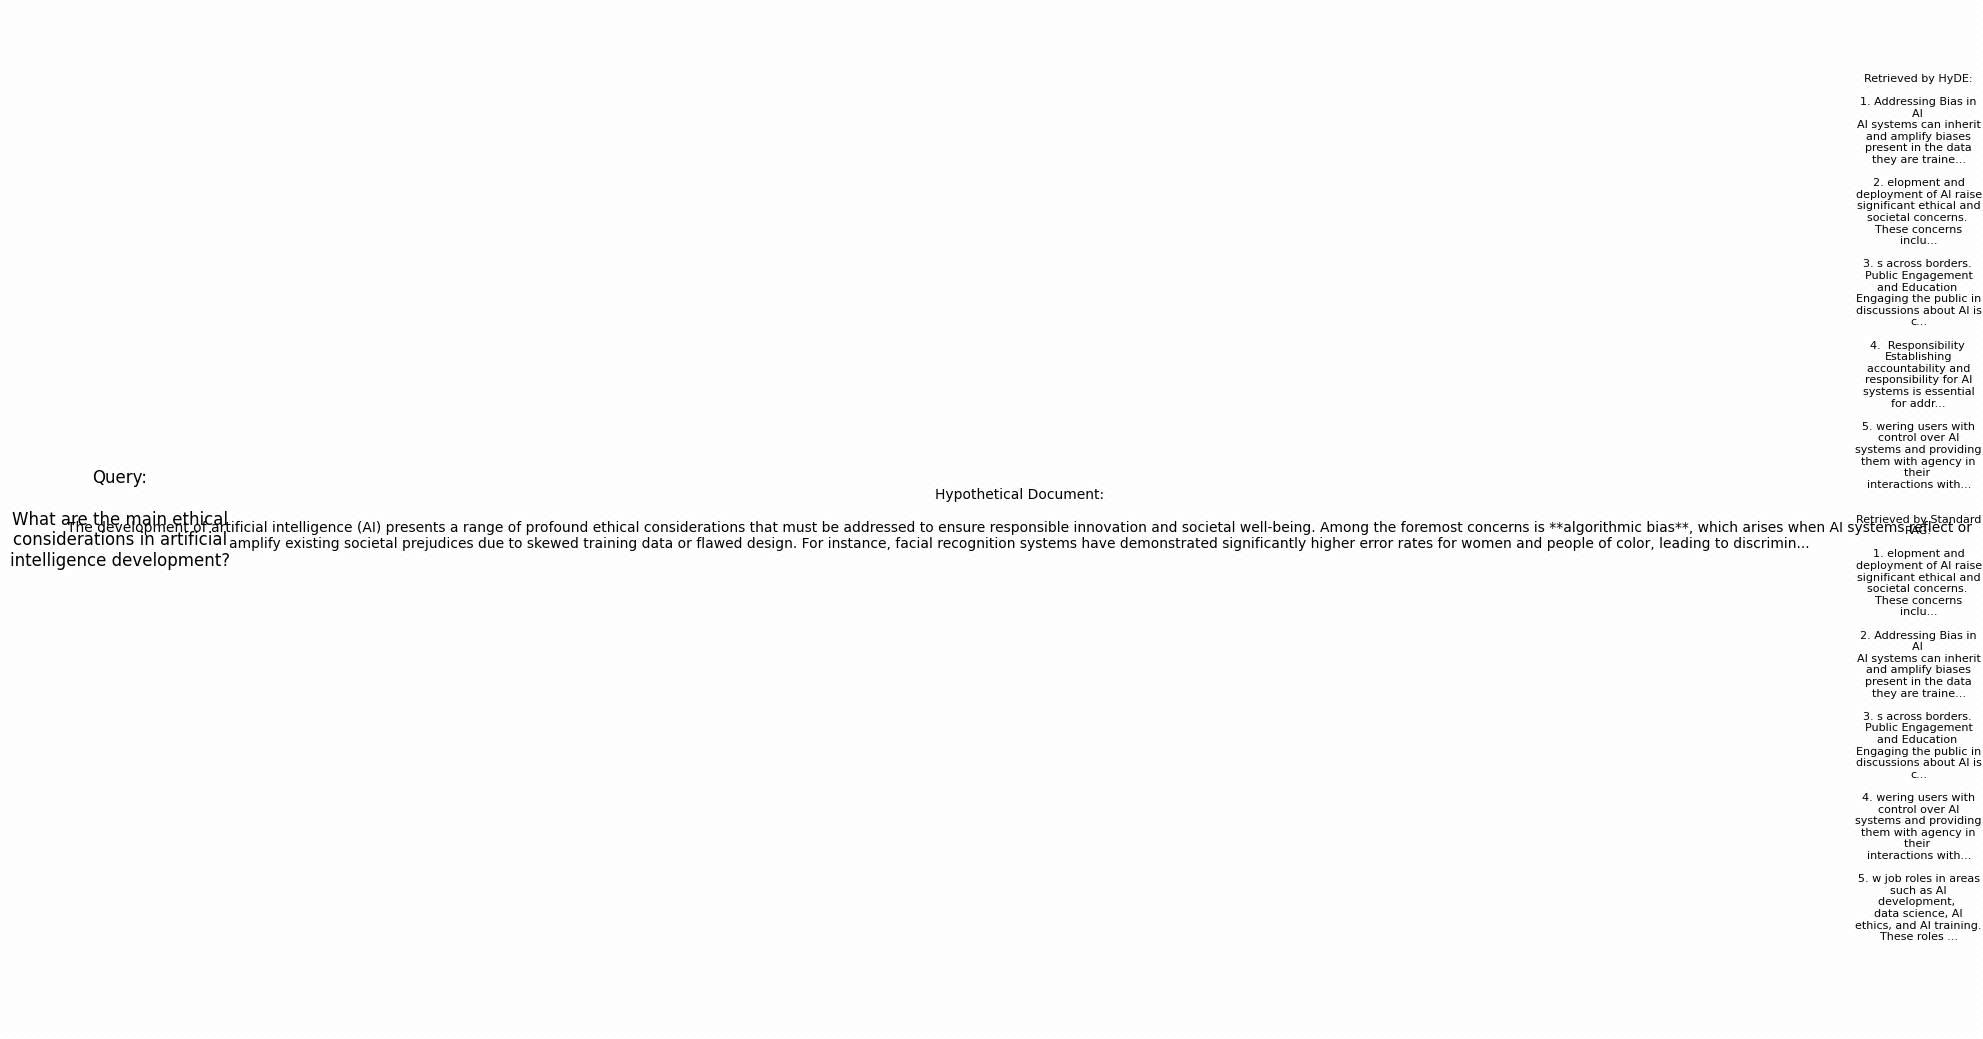

Extracting text from data/AI_Information.pdf...
Extracted 15 pages with content
Created 4 text chunks
Created 4 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 3 text chunks
Created 4 text chunks
Created 3 text chunks
Creating embeddings for chunks...


Vector store created with 48 chunks


===== Evaluating Query 1/1 =====
Query: How does neural network architecture impact AI performance?

=== Processing query with HyDE: How does neural network architecture impact AI performance? ===

Generating hypothetical document...


Generated hypothetical document of 2567 characters
Creating embedding for hypothetical document...
Retrieving 5 most similar chunks...
Generating final response...



=== Processing query with Standard RAG: How does neural network architecture impact AI performance? ===

Creating embedding for query...
Retrieving 5 most similar chunks...
Generating final response...



=== OVERALL ANALYSIS ===
Certainly. Below is a **comprehensive analysis** of HyDE RAG versus Standard RAG, based on the evaluation of **Query 1: "How does neural network architecture impact AI performance?"**, with insights drawn from the comparison across key criteria such as accuracy, relevance, depth, and coherence.

---

## 🔍 **Overall Analysis: HyDE RAG vs. Standard RAG**

### ✅ **When HyDE Outperforms Standard RAG: The Case for Query Understanding & Contextual Depth**

#### **1. Superior Accuracy and Relevance in Conceptual Queries**
- **Why HyDE Wins**: This query is inherently **conceptual and abstract**, requiring an understanding of *how structural choices in neural networks (e.g., CNNs, Transformers, ResNets)* influence downstream AI capabilities like generalization, training speed, and model robustness.
- **HyDE Advantage**: By generating a **hypothetical document (HyDE)** — e.g., *"Neural network architectures such as Transformers enable long-range dependency modeling, le

In [17]:
# AI信息文档的路径
# cache: lpf2-1078c
pdf_path = "data/AI_Information.pdf"

# 处理文档并创建向量存储
# 这会加载文档、提取文本、分块并生成嵌入
vector_store = process_document(pdf_path)

# 示例1：针对单一AI相关查询进行直接比较
query = "What are the main ethical considerations in artificial intelligence development?"

# 运行HyDE RAG方法
# 这会生成一个回答查询的假设文档，对其进行嵌入，
# 然后使用该嵌入来检索相关的片段
hyde_result = hyde_rag(query, vector_store)
print("\n=== HyDE Response ===")
print(hyde_result["response"])

# 运行标准RAG方法进行对比
# 这会直接对查询进行嵌入，并使用它来检索相关的片段
standard_result = standard_rag(query, vector_store)
print("\n=== Standard RAG Response ===")
print(standard_result["response"])

# 可视化HyDE和标准RAG方法之间的差异
# 显示查询、假设文档和检索到的片段并排
visualize_results(query, hyde_result, standard_result)

# 示例2：使用多个AI相关查询运行全面评估
test_queries = [
    "How does neural network architecture impact AI performance?"
]

# 可选的参考答案以实现更好的评估
reference_answers = [
    "Neural network architecture significantly impacts AI performance through factors like depth (number of layers), width (neurons per layer), connectivity patterns, and activation functions. Different architectures like CNNs, RNNs, and Transformers are optimized for specific tasks such as image recognition, sequence processing, and natural language understanding respectively.",
]

# 运行综合评估，比较HyDE和标准RAG方法
evaluation_results = run_evaluation(
    pdf_path=pdf_path,
    test_queries=test_queries,
    reference_answers=reference_answers
)

# 打印跨查询哪种方法表现更好的总体分析
print("\n=== OVERALL ANALYSIS ===")
print(evaluation_results["overall_analysis"])